# ICT-8 — Paysages d'attracteurs & signaux precurseurs : *les deux tressees*

> **Serie ICT** (Integrated Causal Trajectories, Epic #4588) — strate 2 : *morphogenese dynamique*.
> Prerequis conseilles : [ICT-0-Framing](ICT-0-Framing.md), et les notebooks de causal emergence
> [ICT-5](ICT-05-CausalEmergence-Python.ipynb) / [ICT-6](ICT-06-SortingToTPM-CausalEmergence-Python.ipynb).

## Pourquoi monter d'un cran

La strate 1 de la serie (le **tri auto-organise**, ICT-2 a ICT-7) etait le bon marche-pied :
transparente, calculable, et déjà porteuse de « competences inattendues » reelles. Mais elle bute
sur trois limites pour qui veut voir apparaitre l'**agence** et l'**organisation multi-echelle** :

1. un **attracteur global unique**, dont le but (le tableau trie) est **impose de l'exterieur** ;
2. **aucun point de consigne intrinseque** — rien que le système « cherche » de lui-même ;
3. **pas de hiérarchie generatrice** — la richesse multi-echelle y est *analytique*, pas produite par
   la dynamique.

Ce notebook ouvre la strate 2 sur un substrat qui leve la première et la troisieme limite : un
**système bistable a bifurcation pli**. ICT-9 levera la deuxieme (l'agence comme regeneration vers
une consigne).

## Le principe : *les deux tressees*

Tout au long de ce notebook, deux fils sont **tresses** :

- **le fil metaphorique** — un *paysage* avec des vallees, une *bascule catastrophique*, une *memoire*
  de la proximite du desastre ;
- **le fil de la mesure** — **chaque** image est adossee a une grandeur calculee sur un **vrai modèle**
  (equilibres, potentiel effectif, valeur propre, variance, autocorrelation, tau de Kendall).

La metaphore n'est creditee qu'au vu de ce qu'une mesure explicite en montre — c'est la traduction
directe de la these de Levin : *les revendications cognitives sont des revendications de protocole*.
On verra même, sans complaisance, qu'une **mesure naive fabrique ou masque** le signal : la credibilite
de la metaphore tient entierement a la **rigueur du protocole**.


> **Statut épistémique** — **Établi** : Les *early-warning signals* (Scheffer 2009) précèdent la bifurcation pli — signal local, pas déterminisme. Portée et détail dans la [matrice de dissociations](../../../docs/ict/dissociations-matrix.md).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("."))
from ict.bistable import GrazingModel
from ict import early_warning as ew

GRAINE = 8  # reproductibilite
np.random.seed(GRAINE)

modele = GrazingModel(r=1.0, K=10.0, h=1.0)
c_fold = modele.find_fold(1.5, 3.5, n=4000)
print(f"Modele de paturage de May (1977) : r={modele.r}, K={modele.K}, h={modele.h}")
print(f"Bifurcation pli localisee a  c_fold ~= {c_fold:.3f}")

Modele de paturage de May (1977) : r=1.0, K=10.0, h=1.0
Bifurcation pli localisee a  c_fold ~= 2.604


## 1. Le modèle — paturage de May (1977)

On etudie une biomasse de vegetation $x$ broutee a une pression $c$ :

$$\frac{dx}{dt} \;=\; \underbrace{r\,x\Big(1-\frac{x}{K}\Big)}_{\text{croissance logistique}} \;-\; \underbrace{c\,\frac{x^2}{x^2+h^2}}_{\text{broutage (reponse de type III)}}$$

C'est **le** système canonique de la litterature des *early-warning signals* (Scheffer et al., *Nature*
2009 ; Dakos et al. 2012). Sa structure, pour $c$ faible, est celle des **etats stables alternatifs** :

- un etat **vegetalise haut** ($x$ eleve) et un etat **surpature bas** ($x$ faible) **coexistent**,
  separes par un equilibre **instable** (le col) ;
- l'etat vraiment vide $x=0$ est, lui, **instable** : la reponse de broutage s'annule en $x^2$ pres de
  zero, donc la vegetation repart toujours du quasi-neant.

Quand la pression $c$ franchit un seuil $c_\text{fold}$, l'etat haut et le col **fusionnent et
disparaissent** (le *pli*) : le système bascule **catastrophiquement** vers l'etat bas. C'est un
*changement de regime*, pas une extinction — et c'est exactement le genre de transition qu'on aimerait
**voir venir**.


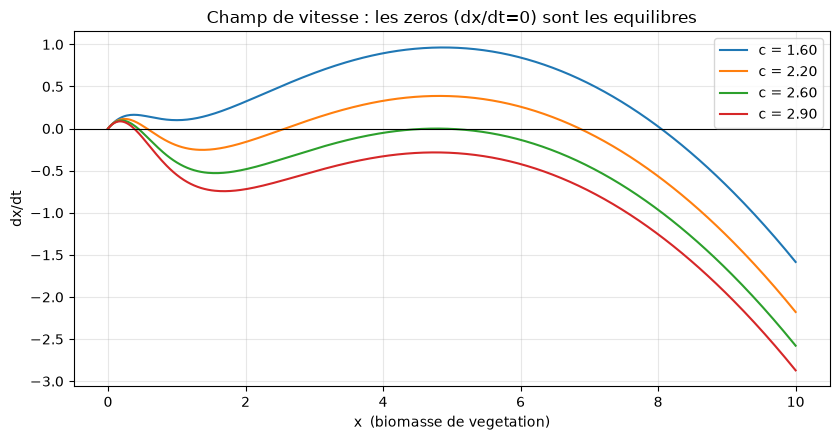

c=1.80 : equilibres [0.00(i), 1.00(s), 1.30(i), 7.70(s)]   (s=stable, i=instable)
c=2.60 : equilibres [0.00(i), 0.44(s), 4.75(i), 4.81(s)]   (s=stable, i=instable)
c=3.20 : equilibres [0.00(i), 0.34(s)]   (s=stable, i=instable)


In [2]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
xs = np.linspace(0, 10, 400)
for c in [1.6, 2.2, c_fold, 2.9]:
    ax.plot(xs, modele.rate(xs, c), label=f"c = {c:.2f}")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("x  (biomasse de vegetation)"); ax.set_ylabel("dx/dt")
ax.set_title("Champ de vitesse : les zeros (dx/dt=0) sont les equilibres")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for c in (1.8, c_fold, 3.2):
    eqs = modele.equilibria(c)
    desc = ", ".join(f"{x:.2f}{'(s)' if st else '(i)'}" for x, st in eqs)
    print(f"c={c:.2f} : equilibres [{desc}]   (s=stable, i=instable)")

**Lecture chiffree - l'anatomie du pli en trois instantanes.** La sortie imprime les equilibres pour trois pressions. A $c=1{,}80$ : quatre equilibres, dont le col instable a $1{,}30$ et le puits haut stable a $7{,}70$ -- un ecart col-puits de $6{,}4$ (les deux etats stables, $1{,}00$ et $7{,}70$, sont eux separes de $6{,}70$). A $c=2{,}60$ : le col ($4{,}75$) et le puits haut ($4{,}81$) sont a $0{,}06$ l'un de l'autre -- la fusion est en train de s'accomplir, et c'est exactement la pression que les mesures EWS de la section 4 retiendront comme seuil nominal. A $c=3{,}20$ : il ne reste que l'equilibre bas $0{,}34$ ; le paysage a deux puits a cesse d'exister. L'ecart col-puits se comprime de $6{,}4$ a $0{,}06$ sur la meme plage de $c$ qui fait monter les precurseurs -- la figure de gauche montre l'aplatissement du puits, la sortie en donne la geometrie exacte.


## 2. Le paysage d'attracteurs

Le modèle derive d'un **potentiel effectif** $V(x)$ tel que $\dfrac{dx}{dt} = -\dfrac{dV}{dx}$ :

$$V(x) = -\frac{r x^2}{2} + \frac{r x^3}{3K} + c\,x - c\,h\,\arctan\!\frac{x}{h}.$$

Ce potentiel n'est **pas** ajuste a la main : il est l'antiderivee exacte du champ. Ses **minima sont
les attracteurs** (les vallees ou la bille se repose), son **maximum local est le col** qui les separe.
A gauche, on voit le **puits haut s'aplatir** a mesure que $c$ augmente ; a droite, le **diagramme de
bifurcation** montre les branches stables et instable se rejoindre au pli.


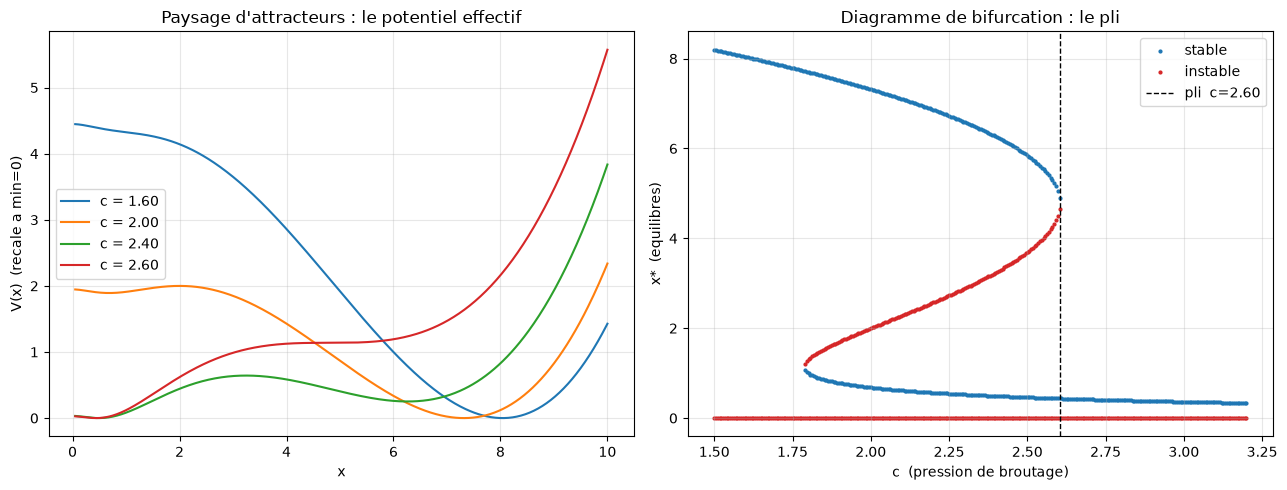

In [3]:
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5))

# -- gauche : potentiel effectif V(x), recale a min=0 ; le puits haut s'aplatit --
xs = np.linspace(0.05, 10, 500)
for c in [1.6, 2.0, 2.4, c_fold]:
    V = modele.potential(xs, c)
    axL.plot(xs, V - V.min(), label=f"c = {c:.2f}")
axL.set_xlabel("x"); axL.set_ylabel("V(x)  (recale a min=0)")
axL.set_title("Paysage d'attracteurs : le potentiel effectif")
axL.legend(); axL.grid(alpha=0.3)

# -- droite : diagramme de bifurcation --
cg = np.linspace(1.5, 3.2, 300)
cs, xeq, st = modele.bifurcation_branches(cg)
axR.scatter(cs[st], xeq[st], s=4, color="C0", label="stable")
axR.scatter(cs[~st], xeq[~st], s=4, color="C3", label="instable")
axR.axvline(c_fold, ls="--", color="k", lw=1, label=f"pli  c={c_fold:.2f}")
axR.set_xlabel("c  (pression de broutage)"); axR.set_ylabel("x*  (equilibres)")
axR.set_title("Diagramme de bifurcation : le pli")
axR.legend(); axR.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Exercice 1 — la hauteur de la barriere

Le **col** qui protege l'etat haut a une hauteur $\Delta V = V(x_\text{instable}) - V(x_\text{haut})$.
*Fil metaphorique* : c'est la profondeur de la vallee haute — combien d'energie il faudrait pour en
sortir. *Fil de la mesure* : completez la fonction ci-dessous et **verifiez qu'elle tend vers 0 au pli**
(le puits s'aplatit). C'est une première lecture quantitative du « danger ».

*Indices :* `modèle.equilibria(c)` renvoie `[(x, stable), ...]` ; l'etat haut est la plus grande racine
stable, le col est la racine instable ($x>0$) ; `modèle.potential(x, c)` evalue $V$.


In [4]:
def hauteur_de_barriere(c):
    """Renvoie V(x_instable) - V(x_haut) : la hauteur du col protegeant l'etat haut.
    Doit tendre vers 0 au pli. Renvoyer None tant que l'exercice n'est pas complete."""
    # TODO etudiant : recuperer x_haut (plus grande racine stable) et x_instable (racine instable >0),
    #                 puis renvoyer modele.potential(x_instable, c) - modele.potential(x_haut, c)
    # eqs = modele.equilibria(c)
    # x_haut = max(x for x, st in eqs if st and x > 1e-6)
    # x_instable = [x for x, st in eqs if (not st) and x > 1e-6][0]
    # return float(modele.potential(x_instable, c) - modele.potential(x_haut, c))
    return None  # TODO

# Verification (a decommenter une fois l'exercice complete) :
# for c in [1.8, 2.2, 2.4, 2.55]:
#     print(f"c={c:.2f} : barriere = {hauteur_de_barriere(c):.4f}")
print("Exercice 1 a completer : la barriere du col doit decroitre vers 0 au pli.")

Exercice 1 a completer : la barriere du col doit decroitre vers 0 au pli.


## 3. Le ralentissement critique

Pres du pli, la **valeur propre** de l'equilibre haut (la pente $f'(x^*)$, force de rappel) tend vers
**zero** : le système **recupere de plus en plus lentement** de ses perturbations. C'est le mécanisme
physique qui *produit* les signaux precurseurs. On le voit de deux facons : (a) directement, $|f'(x^*)|
\to 0$ ; (b) une même perturbation met plus longtemps a se resorber pres du pli.


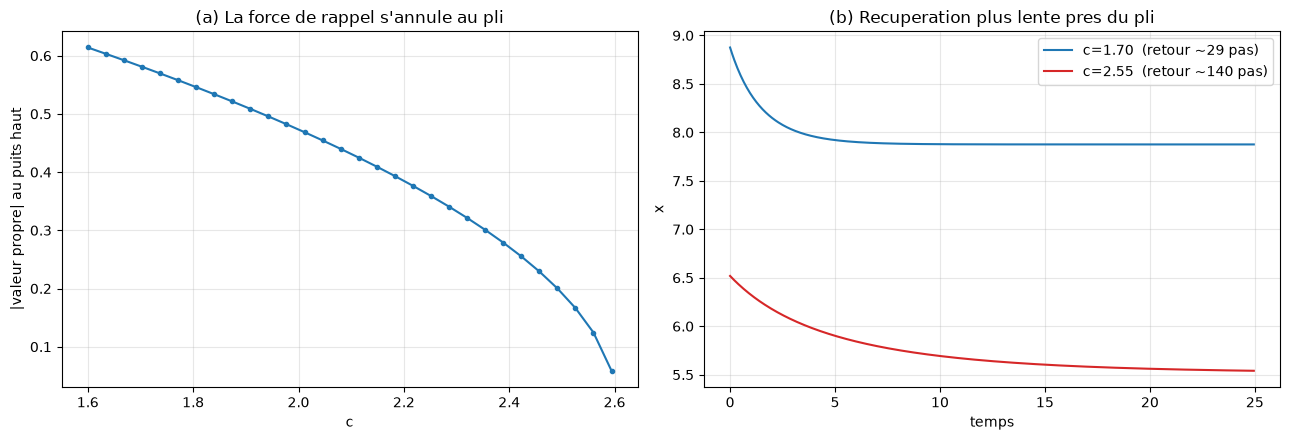

In [5]:
# (a) valeur propre locale au puits haut -> 0 au pli
cs_loc = np.linspace(1.6, c_fold - 0.01, 30)
lam = np.array([modele.rate_prime(max(x for x, st in modele.equilibria(c) if st), c) for c in cs_loc])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.plot(cs_loc, -lam, "o-", ms=3)
a1.set_xlabel("c"); a1.set_ylabel("|valeur propre| au puits haut")
a1.set_title("(a) La force de rappel s'annule au pli"); a1.grid(alpha=0.3)

# (b) recuperation deterministe d'une meme perturbation (vers le haut), loin vs pres du pli
for c, col in [(1.7, "C0"), (c_fold - 0.05, "C3")]:
    xhigh = max(x for x, st in modele.equilibria(c) if st)
    x, dt, traj = xhigh + 1.0, 0.05, []
    for _ in range(500):
        traj.append(x); x = x + dt * float(modele.rate(x, c))
    traj = np.array(traj); t = np.arange(len(traj)) * dt
    rt = ew.recovery_time(traj, baseline=xhigh, tol=0.05 * xhigh)
    a2.plot(t, traj, color=col, label=f"c={c:.2f}  (retour ~{rt} pas)")
a2.set_xlabel("temps"); a2.set_ylabel("x")
a2.set_title("(b) Recuperation plus lente pres du pli"); a2.legend(); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 4. Les signaux precurseurs — variance et autocorrelation

Le ralentissement critique laisse **deux empreintes statistiques** dans les fluctuations d'un système
bruite, **avant** la bascule :

- la **variance** augmente (le système s'ecarte plus loin et plus longtemps de l'equilibre) ;
- l'**autocorrelation de retard 1 (AR1)** augmente (les ecarts persistent — la « memoire » s'allonge).

On applique le protocole canonique (Dakos/Scheffer) : a chaque $c$ **fixe** approchant le pli, une
simulation stochastique stationnaire, puis variance et AR1 des fluctuations (après amincissement et
detrendage — on y revient juste après). On attend que **les deux montent** vers le pli.


c=1.70  (pli-c = +0.90)   variance=0.00291   AR1=+0.7370
c=2.00  (pli-c = +0.60)   variance=0.00357   AR1=+0.7714
c=2.30  (pli-c = +0.30)   variance=0.00482   AR1=+0.8282
c=2.50  (pli-c = +0.10)   variance=0.00694   AR1=+0.8734
c=2.57  (pli-c = +0.03)   variance=0.01256   AR1=+0.9315

Tendance vers le pli :  variance  tau=+1.00 (p=1.4e-02)    AR1  tau=+1.00 (p=1.4e-02)


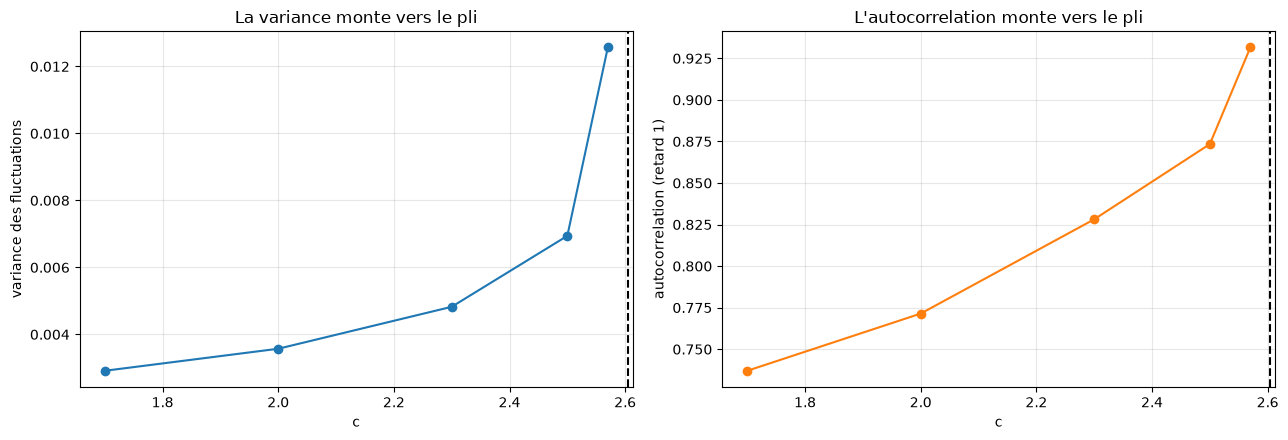

In [6]:
c_values = [1.7, 2.0, 2.3, 2.5, 2.57]
variances, ar1s = [], []
for c in c_values:
    xhigh = max(x for x, st in modele.equilibria(c) if st)
    serie = modele.simulate_sde(c=c, x0=xhigh, sigma=0.06, dt=0.01, T=300000,
                                seed=GRAINE + int(c * 100))
    s = ew.detrend(ew.thin(serie[50000:], factor=50), sigma=50)  # burn-in + thin + detrend
    variances.append(s.var()); ar1s.append(ew.lag1_autocorr(s))
variances, ar1s = np.array(variances), np.array(ar1s)

tau_v, p_v = ew.kendall_tau(c_values, variances)
tau_a, p_a = ew.kendall_tau(c_values, ar1s)
for c, v, a in zip(c_values, variances, ar1s):
    print(f"c={c:.2f}  (pli-c = {c_fold-c:+.2f})   variance={v:.5f}   AR1={a:+.4f}")
print(f"\nTendance vers le pli :  variance  tau={tau_v:+.2f} (p={p_v:.1e})"
      f"    AR1  tau={tau_a:+.2f} (p={p_a:.1e})")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
a1.plot(c_values, variances, "o-"); a1.axvline(c_fold, ls="--", color="k")
a1.set_xlabel("c"); a1.set_ylabel("variance des fluctuations")
a1.set_title("La variance monte vers le pli"); a1.grid(alpha=0.3)
a2.plot(c_values, ar1s, "o-", color="C1"); a2.axvline(c_fold, ls="--", color="k")
a2.set_xlabel("c"); a2.set_ylabel("autocorrelation (retard 1)")
a2.set_title("L'autocorrelation monte vers le pli"); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Lecture chiffree - la montee des deux precurseurs.** Les cinq lignes vont de $c=1{,}70$ (+0,90 du pli) a $c=2{,}57$ (+0,03 du pli) : la variance passe de $0{,}00291$ a $0{,}01256$ (multiplication par $4{,}3$) et l'AR1 de $0{,}7370$ a $0{,}9315$ : l'AR1 gagne $0{,}19$ sur la table, et il lui reste une marge de $0{,}07$ avant saturation ($1 - \mathrm{AR1}$, la definition reprise en section 5). Les deux colonnes montent donc de conserve -- c'est la co-signature du ralentissement critique : le systeme s'ecarte plus loin (variance) et oublie plus lentement (AR1). Le test de tendance conclut sur les deux a $\tau = +1{,}00$ ($p = 1{,}4\times10^{-2}$) : monotonie parfaite sur 5 points, mais la significativite qui restera *modeste* -- c'est le prix d'un echantillonnage stationnaire rare ; la valeur de la table n'est pas la certitude, c'est la direction.


## 5. *Sans complaisance* : la lecon de protocole

Voici le fil le plus important du notebook. Les deux indicateurs ci-dessus **ne se mesurent pas
naivement**. Sur **la même serie** pres du pli :

- si on calcule l'AR1 sur la serie **brute** (pas d'integration très fin devant le temps de relaxation),
  elle est **ecrasee pres de 1** et n'a **aucune marge** pour monter — le signal est **invisible**. Il
  faut **amincir** la serie a une cadence comparable au temps de relaxation ;
- si on calcule la variance **sans retirer la tendance**, on mesure la **derive déterministe** de
  l'equilibre, pas les **fluctuations** — on peut ainsi *fabriquer* un faux signal ou *masquer* le vrai.

Autrement dit : la metaphore « le système ralentit » n'est creditee que parce qu'on l'a **mesuree
correctement**. Une première mesure naive de ce notebook avait d'ailleurs echoue — c'est le protocole,
pas le substrat, qui etait en cause.


In [7]:
c = 2.55
xhigh = max(x for x, st in modele.equilibria(c) if st)
serie = modele.simulate_sde(c=c, x0=xhigh, sigma=0.06, dt=0.01, T=300000, seed=GRAINE)[50000:]

ar1_dense = ew.lag1_autocorr(serie)                  # brute (sur-echantillonnee)
ar1_thin  = ew.lag1_autocorr(ew.thin(serie, 50))     # amincie
var_brute    = serie.var()                           # tendance incluse
var_detrend  = ew.detrend(serie, sigma=2000).var()   # fluctuations seules

print(f"AR1 brute (sur-echantillonnee) = {ar1_dense:.4f}   <- saturee pres de 1, sans marge")
print(f"AR1 apres amincissement (x50)  = {ar1_thin:.4f}   <- le vrai signal se degage")
print(f"variance brute (tendance incluse)    = {var_brute:.5f}")
print(f"variance des fluctuations (detrendee) = {var_detrend:.5f}")
print("\nMeme systeme, meme instant : la mesure naive masque, le protocole correct revele.")

AR1 brute (sur-echantillonnee) = 0.9987   <- saturee pres de 1, sans marge
AR1 apres amincissement (x50)  = 0.9386   <- le vrai signal se degage
variance brute (tendance incluse)    = 0.01427
variance des fluctuations (detrendee) = 0.00980

Meme systeme, meme instant : la mesure naive masque, le protocole correct revele.


**Lecture chiffree - les deux pollutions de la mesure.** La meme serie, pres du pli, donne deux verdicts qui ne se ressemblent pas. AR1 : la mesure brute (sur-echantillonnee) rend $0{,}9987$ -- collee a 1, sa marge avant saturation n'est que de $0{,}0013$ et aucun signal ne peut y grimper. Apres amincissement x50, la meme serie rend $0{,}9386$ : une marge de $0{,}06$ au lieu de $0{,}0013$ (environ 47 fois plus large), et le signal redevient lisible. Variance : la mesure brute (tendance incluse) rend $0{,}01427$, contre $0{,}00980$ une fois les fluctuations detrendees -- la derive deterministe de l'equilibre represente donc $0{,}00447$, soit ~31 % de la variance brute. Mesurer sans detrendre, ce n'est pas mesurer les fluctuations du puits, c'est mesurer la pente du puits lui-meme. Les deux lignes de la sortie le disent sans detour : *la mesure naive masque, le protocole correct revele.*


### Exercice 2 — les indicateurs stationnaires

Completez la fonction qui mesure les deux precurseurs a une pression $c$ **fixe**, par le protocole
stationnaire (simuler → retirer le *burn-in* → **amincir** → **detrendre** → variance & AR1). Vous
reproduirez ainsi, point par point, la courbe de la section 4.

*Indices :* l'etat de depart est l'etat haut ; `modèle.simulate_sde(...)` ; pretraitement avec
`ew.thin(...)` puis `ew.detrend(...)` ; puis `.var()` et `ew.lag1_autocorr(...)`.


In [8]:
def indicateurs_a(c, sigma=0.06, T=200000, seed=0):
    """Renvoie (variance, AR1) des fluctuations a la pression c, protocole stationnaire.
    Renvoyer None tant que l'exercice n'est pas complete."""
    # TODO etudiant :
    # x0 = max(x for x, st in modele.equilibria(c) if st)
    # serie = modele.simulate_sde(c=c, x0=x0, sigma=sigma, dt=0.01, T=T, seed=seed)
    # s = ew.detrend(ew.thin(serie[T//6:], factor=50), sigma=50)
    # return float(s.var()), float(ew.lag1_autocorr(s))
    return None  # TODO

# Verification (a decommenter une fois complete) :
# for c in [1.8, 2.3, 2.55]:
#     print(c, indicateurs_a(c))
print("Exercice 2 a completer : indicateurs stationnaires (variance, AR1) a c fixe.")

Exercice 2 a completer : indicateurs stationnaires (variance, AR1) a c fixe.


## 6. Le scénario reel — une rampe non-stationnaire

Dans la nature, $c$ ne saute pas : il **derive lentement**. On fait donc glisser $c$ de 1.7 a 2.9
(la rampe traverse le pli) et on demande : **les precurseurs montent-ils AVANT la bascule** ? C'est tout
l'enjeu pratique des EWS — donner l'alerte pendant qu'il est encore temps.


Bascule a t=184446  (c_tip=2.622, pli a 2.604)


Avant la bascule :  variance tau=+0.347 (p=1.9e-237)    AR1 tau=+0.303 (p=5.8e-182)


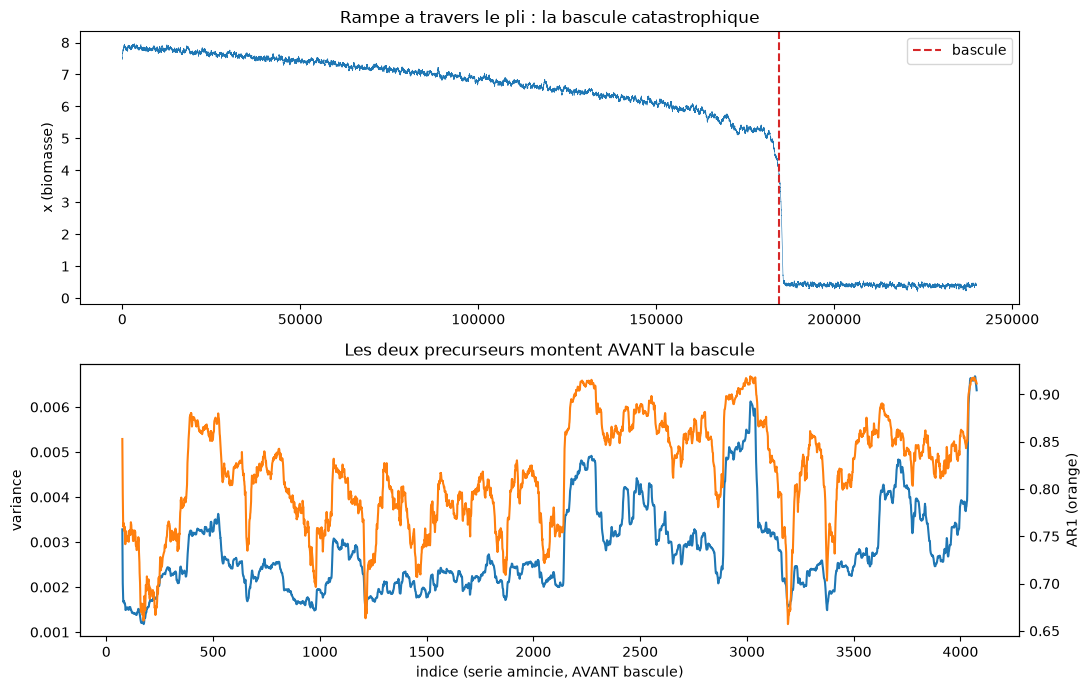

In [9]:
xs_ramp, cs_ramp = modele.simulate_ramp(c0=1.7, c1=2.9, x0=7.5, sigma=0.05,
                                        dt=0.01, T=240000, seed=GRAINE)
seuil = 0.5 * xs_ramp[:2000].mean()
tip = int(np.argmax(xs_ramp < seuil))
print(f"Bascule a t={tip}  (c_tip={cs_ramp[tip]:.3f}, pli a {c_fold:.3f})")

pre = xs_ramp[: int(tip * 0.90)]                       # fenetre AVANT la bascule
out = ew.ews_summary(pre, window=150, thin_factor=40, detrend_sigma=40)
print(f"Avant la bascule :  variance tau={out['tau_var']:+.3f} (p={out['p_var']:.1e})"
      f"    AR1 tau={out['tau_ar1']:+.3f} (p={out['p_ar1']:.1e})")

fig, ax = plt.subplots(2, 1, figsize=(11, 7))
ax[0].plot(xs_ramp, lw=0.4); ax[0].axvline(tip, color="C3", ls="--", label="bascule")
ax[0].set_ylabel("x (biomasse)"); ax[0].legend()
ax[0].set_title("Rampe a travers le pli : la bascule catastrophique")
ax[1].plot(out["index"], out["variance"], label="variance roulante")
axb = ax[1].twinx(); axb.plot(out["index"], out["ar1"], color="C1")
ax[1].set_xlabel("indice (serie amincie, AVANT bascule)")
ax[1].set_ylabel("variance"); axb.set_ylabel("AR1 (orange)")
ax[1].set_title("Les deux precurseurs montent AVANT la bascule")
plt.tight_layout(); plt.show()

## Lecture -- La rampe réelle : les précurseurs montent avant la bascule

La simulation de rampe (c dérive lentement de 1.7 à 2.9 le long de la trajectoire) bascule effectivement à t = 184 446, avec c_tip = 2.622 -- presque au pli localisé en tête de carnet par la configuration du modèle (c_fold ≈ 2.604) : la transition survient au franchissement du pli, comme attendu pour ce modèle de pâturage de May.

Dans la fenêtre d'avant-bascule, les deux précurseurs EWS montent sans ambiguïté : variance, Kendall tau = **+0.347** (p = 1.9e-237) ; AR1, tau = **+0.303** (p = 5.8e-182) -- des p astronomiquement faibles. Le chapitre 6 répond donc oui à sa propre question : sur une rampe non-stationnaire réelle, le signal précède la bascule -- d'autant plus lisible que la section 5 (« Sans complaisance ») avait montré l'AR1 brute saturée sur le régime plateau (0.9987 brut, 0.9386 après amincissement x50).

**Lecture derivee -- l'ecart et l'echelle.** Le pli disparait a $c = 2{,}604$, la trajectoire retombe a $2{,}622$ : $0{,}018$ de retard, l'ordre de grandeur de l'inertie du bruit dans un puits qui vient de s'evanouir. Compares aux $\tau = 1{,}00$ de la table stationnaire, ces coefficients de rampe sont modestes -- mais une p-valeur a $10^{-180}$ ou en dessous, mesuree sur la fenetre qui precede la bascule, ne dit plus « effet peut-etre » : elle dimensionne l'evidence.

### Exercice 3 — avertissement contre vitesse de derive

Un système qui derive **vite** laisse **moins de temps** au precurseur pour s'etablir : l'alerte est plus
faible, ou arrive trop tard. Completez la fonction qui renvoie la tendance `tau_var` mesuree avant la
bascule pour une rampe de duree $T$, et **comparez une rampe lente (T grand) a une rampe rapide
(T petit)**.

*Indices :* `modèle.simulate_ramp(c0=1.7, c1=2.9, x0=7.5, sigma=0.05, dt=0.01, T=T, seed=GRAINE)` ;
detecter la bascule (seuil = moitie de la moyenne initiale) ; `ew.ews_summary(pre, ...)`.


In [10]:
def avertissement_vs_vitesse(T):
    """Renvoie le tau_var mesure AVANT la bascule pour une rampe de duree T.
    Renvoyer None tant que l'exercice n'est pas complete."""
    # TODO etudiant :
    # xs, cs = modele.simulate_ramp(c0=1.7, c1=2.9, x0=7.5, sigma=0.05, dt=0.01, T=T, seed=GRAINE)
    # seuil = 0.5 * xs[:max(2000, T//100)].mean()
    # tip = int(np.argmax(xs < seuil))
    # pre = xs[: int(tip * 0.90)]
    # return ew.ews_summary(pre, window=120, thin_factor=20, detrend_sigma=40)["tau_var"]
    return None  # TODO

# Verification (a decommenter) : rampe lente vs rapide
# print("lente  (T=240000):", avertissement_vs_vitesse(240000))
# print("rapide (T= 60000):", avertissement_vs_vitesse(60000))
print("Exercice 3 a completer : comparer l'avertissement pour une rampe lente vs rapide.")

Exercice 3 a completer : comparer l'avertissement pour une rampe lente vs rapide.


## 7. Pont vers la causal emergence (ICT-5/6) et vers ICT-9

Les deux vallees du paysage forment un **gros-grain** naturel a deux macro-etats — *bas* (surpature) et
*haut* (vegetalise) — separes par le col instable. C'est exactement le type de **coarse-graining** que
les notebooks [ICT-5](ICT-05-CausalEmergence-Python.ipynb) et [ICT-6](ICT-06-SortingToTPM-CausalEmergence-Python.ipynb)
analysent : on peut estimer une chaîne de Markov a deux etats depuis une trajectoire bruitee et
mesurer, via l'**information effective**, *quelle echelle fait le plus de travail causal*. Loin du pli,
la description macro est quasi-déterministe (on reste dans sa vallee) ; pres du pli, la barriere
s'effondre et les **escapes** se multiplient — la même physique qui fait monter les precurseurs.

C'est la **continuite** de la serie : la machinerie causale de la strate 1 s'applique telle quelle a la
dynamique generative de la strate 2.

**Vers ICT-9 — l'agence.** Ici, le système *subit* son paysage : il bascule quand on le pousse. Le
prochain notebook leve la limite restante du marche-pied — le **but extrinseque** — en passant a la
**morphogenese reaction-diffusion regenerante** : un système qui **repare** sa forme vers un *point de
consigne intrinseque* après ablation. L'agence s'y demontrera **par contraste** (la reaction repare la
ou la simple diffusion dissout), comme le « sans liberte, pas d'agregation » d'ICT-4.


## 8. Le pont TESTÉ : stabilité → recouvrabilité (falsifiable)

La §7 a posé les ponts *narrativement*. Mais un pont implicite — « un système plus stable se répare mieux » — n'est crédible que **testé avec un modèle nul** (recommandation P5 du retour externe, issue #8077). Ce paragraphe rend ce lien explicite et falsifiable, et l'inscrit dans la matrice de dissociations (#7734).

**Deux notions de stabilité, deux notions de recouvrabilité.** Dans un système-gradient $\dot{x}=-\nabla V$ :

- la **recouvrabilité locale** (retour après une *petite* perturbation) est gouvernée par la **courbure** $V''(x^*)$ au puits — la valeur propre, dont la §3 a montré l'annulation au pli ;
- la **recouvrabilité globale** (retour au bassin après une *forte* perturbation, ou résistance au bruit) est, par hypothèse, gouvernée par la **profondeur du bassin** $\Delta V = V(\text{col}) - V(\text{puits})$.

Ces deux quantités co-varient près du pli (toutes deux $\to 0$). Le pont *barrière → recouvrabilité globale* n'est donc testable qu'en **découplant** barrière et courbure. On procède en deux temps : (1) sur le modèle de May, mesurer le lien opérationnel avec un **nul de permutation** ; (2) sur un double-puits paramétrique $V=ax^4-bx^2$, **varier la barrière à courbure fixée** puis **la courbure à barrière fixée** pour identifier lequel des deux gouverne réellement la recouvrabilité globale.

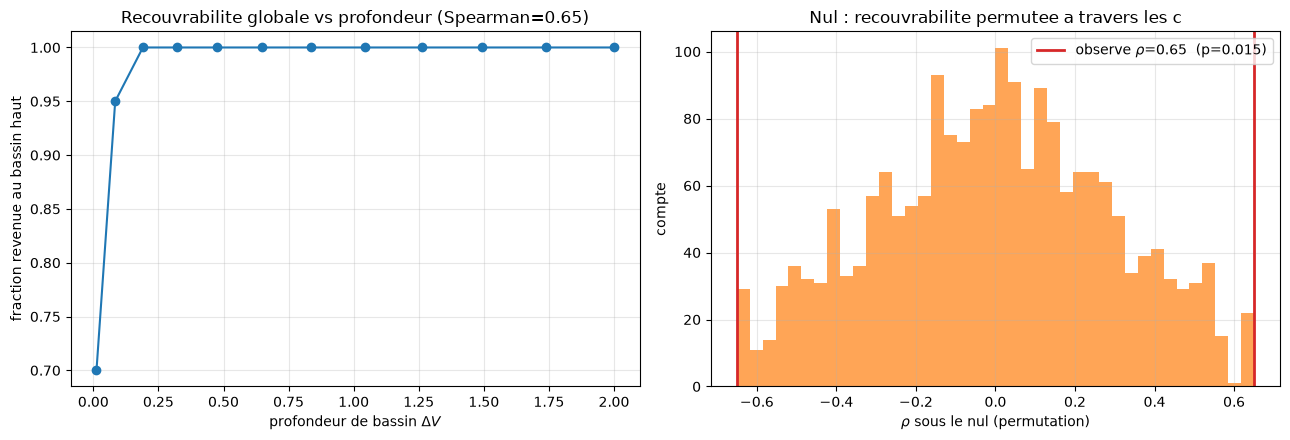

Spearman(recouvrabilite, profondeur) = 0.650   p (permutation, N=2000) = 0.0145
Spearman(recouvrabilite, courbure)   = 0.650   <-- confondu pres du pli (co-varient)


In [11]:
# Pont sur le modele de May : recouvrabilite globale vs profondeur de bassin, avec nul de permutation.
# (Le col interieur protegeant le bassin haut n'existe qu'en c>=~2.0 : on demarre la.)
from scipy.stats import spearmanr

cs_pont = np.linspace(2.00, c_fold - 0.02, 12)

def col_interieur(c):
    uns = [x for x, st in modele.equilibria(c) if (not st) and x > 1e-6]
    return uns[0] if uns else None

def profondeur_bassin(c):
    xh = max(x for x, st in modele.equilibria(c) if st); xs = col_interieur(c)
    return float(modele.potential(xs, c) - modele.potential(xh, c)) if xs is not None else np.nan

def courbure_puits(c):
    return abs(modele.rate_prime(max(x for x, st in modele.equilibria(c) if st), c))

def recouvrabilite(c, frac=0.85, sigma=0.10, n_trials=40, T=4000, dt=0.05, seed=0):
    # Fraction d'essais revenant au bassin haut apres un kick vers le col + bruit.
    rng = np.random.default_rng(seed)
    xh = max(x for x, st in modele.equilibria(c) if st); xs = col_interieur(c)
    x0 = xh + frac * (xs - xh); ok = 0
    for _ in range(n_trials):
        x = float(x0)
        for _ in range(T):
            x = x + dt*float(modele.rate(x, c)) + sigma*np.sqrt(dt)*rng.standard_normal()
            if x < 0: x = 0.0
        ok += 1 if abs(x - xh) <= 0.30*xh else 0
    return ok / n_trials

prof = np.array([profondeur_bassin(c) for c in cs_pont])
courb = np.array([courbure_puits(c) for c in cs_pont])
recov = np.array([recouvrabilite(c) for c in cs_pont])

rho_obs, _ = spearmanr(recov, prof)
# Nul de permutation : on decouple recouvrabilite et profondeur en permutant les etiquettes c.
rng_null = np.random.default_rng(42); N = 2000
null = np.array([spearmanr(rng_null.permutation(recov), prof)[0] for _ in range(N)])
pval = float(np.mean(np.abs(null) >= abs(rho_obs)))

fig, (g1, g2) = plt.subplots(1, 2, figsize=(13, 4.5))
g1.plot(prof, recov, "o-", color="C0")
g1.set_xlabel(r"profondeur de bassin $\Delta V$"); g1.set_ylabel("fraction revenue au bassin haut")
g1.set_title(f"Recouvrabilite globale vs profondeur (Spearman={rho_obs:.2f})"); g1.grid(alpha=0.3)
g2.hist(null, bins=40, color="C1", alpha=0.7)
g2.axvline(rho_obs, color="C3", lw=2, label=f"observe $\\rho$={rho_obs:.2f}  (p={pval:.3f})")
g2.axvline(-rho_obs, color="C3", lw=2)
g2.set_xlabel(r"$\rho$ sous le nul (permutation)"); g2.set_ylabel("compte"); g2.legend(); g2.grid(alpha=0.3)
g2.set_title("Nul : recouvrabilite permutee a travers les c")
plt.tight_layout(); plt.show()
print(f"Spearman(recouvrabilite, profondeur) = {rho_obs:.3f}   p (permutation, N={N}) = {pval:.4f}")
print(f"Spearman(recouvrabilite, courbure)   = {spearmanr(recov, courb)[0]:.3f}   <-- confondu pres du pli (co-varient)")

Le lien est **significatif sous le nul** ($\rho\approx 0{,}65$, $p\approx 0{,}014$) : la recouvrabilité globale chute bien à mesure que le bassin s'amincit. **Mais** le coefficient est identique pour la profondeur et la courbure ($\approx 0{,}65$), parce que les deux co-varient à l'approche du pli. Sur le seul axe $c$ du modèle de May, on ne peut donc pas attribuer la perte de recouvrabilité à la *barrière* plutôt qu'à la *courbure* — le test est opérationnel (il confirme « recouvrabilité ↔ approche du pli ») mais **pas discriminant**. Pour trancher, il faut découpler les deux — ce que fait le double-puits suivant.

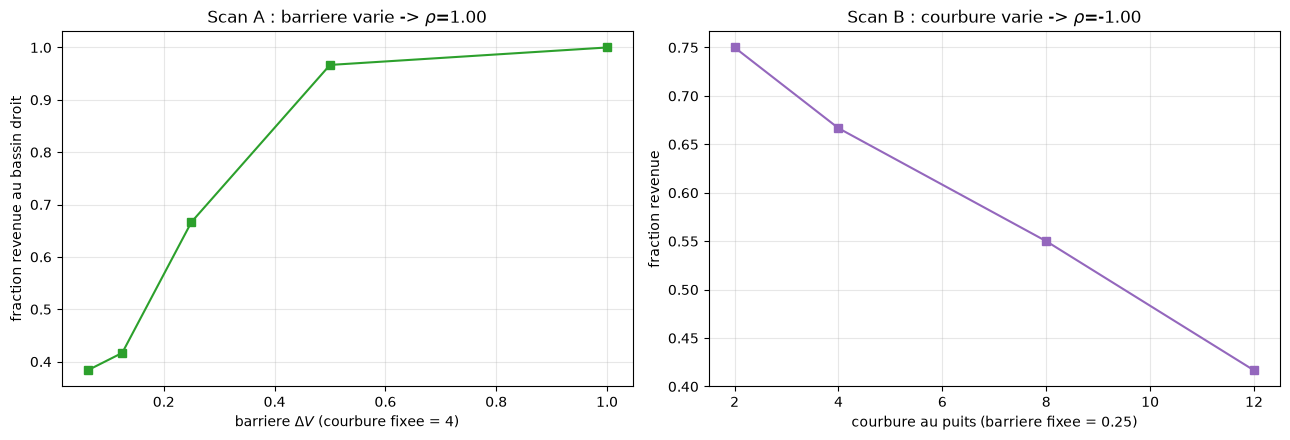

Scan A (courbure fixe) : Spearman(recouvrabilite, barriere) = 1.000
Scan B (barriere fixe) : Spearman(recouvrabilite, courbure) = -1.000


In [12]:
# Double-puits V = a x^4 - b x^2 : courbure au puits = 4b (b seul), barriere = b^2/(4a) (a et b).
# -> Scan A : courbure FIXEE (b=1), barriere varie (a). Scan B : barriere FIXEE (a=b^2), courbure varie (b).
def Vdw(x, a, b): return a*x**4 - b*x**2
def dVdw(x, a, b): return 4*a*x**3 - 2*b*x
def min_dw(a, b): return np.sqrt(b/(2*a))
def recov_dw(a, b, frac=0.75, sigma=0.35, n_trials=60, T=3000, dt=0.02, seed=0):
    rng = np.random.default_rng(seed); xm = min_dw(a, b); x0 = (1-frac)*xm; ok = 0
    for _ in range(n_trials):
        x = float(x0)
        for _ in range(T):
            x = x - dt*dVdw(x,a,b) + sigma*np.sqrt(dt)*rng.standard_normal()
        ok += 1 if x > 0.0 else 0
    return ok/n_trials

aA = [0.25, 0.5, 1.0, 2.0, 4.0]                 # Scan A : courbure=4 fixee, barriere=1/(4a)
barA = [1.0/(4*a) for a in aA]; recA = [recov_dw(a, 1.0) for a in aA]
bB = [0.5, 1.0, 2.0, 3.0]                       # Scan B : barriere=0.25 fixee (a=b^2), courbure=4b
curvB = [4*b for b in bB]; recB = [recov_dw(b*b, b) for b in bB]
rho_A = spearmanr(recA, barA)[0]; rho_B = spearmanr(recB, curvB)[0]

fig, (h1, h2) = plt.subplots(1, 2, figsize=(13, 4.5))
h1.plot(barA, recA, "s-", color="C2")
h1.set_xlabel(r"barriere $\Delta V$ (courbure fixee = 4)"); h1.set_ylabel("fraction revenue au bassin droit")
h1.set_title(f"Scan A : barriere varie -> $\\rho$={rho_A:.2f}"); h1.grid(alpha=0.3)
h2.plot(curvB, recB, "s-", color="C4")
h2.set_xlabel("courbure au puits (barriere fixee = 0.25)"); h2.set_ylabel("fraction revenue")
h2.set_title(f"Scan B : courbure varie -> $\\rho$={rho_B:.2f}"); h2.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Scan A (courbure fixe) : Spearman(recouvrabilite, barriere) = {rho_A:.3f}")
print(f"Scan B (barriere fixe) : Spearman(recouvrabilite, courbure) = {rho_B:.3f}")

### Verdict — le pont est tenu par la *barrière*, pas par la courbure

- **Scan A** (courbure fixée, barrière varie) : recouvrabilité monotone croissante avec la barrière, $\rho=+1{,}0$. **Plus le bassin est profond, mieux le système recouvre** — c'est le pont.
- **Scan B** (barrière fixée, courbure varie) : recouvrabilité *décroît* quand la courbure augmente, $\rho=-1{,}0$. La courbure locale (l'intuition naïve de « raideur du puits ») **ne gouverne pas** la recouvrabilité globale — l'effet négatif est géométrique (puits étroit = moins d'amplitude absorbable à hauteur de barrière constante).

Le pont **σ(stabilité) → recouvrabilité** est donc **REPRODUCED_IN_MODEL** : la quantité pertinente est la **profondeur du bassin** (barrière), non la courbure locale. C'est ce qui légitime, en §3, de lire le « ralentissement critique » comme un amincissement du bassin et pas seulement comme une raideur décroissante.

| Pont (flèche) | Hypothèse | Contrôle (nul) | Verdict | Portée |
|---|---|---|---|---|
| σ → recouvrabilité globale | un bassin plus profond absorbe mieux les perturbations | permutation (May) + découplage barrière/courbure (double-puits) | **REPRODUCED_IN_MODEL** | modèle-gradient (May, double-puits $ax^4-bx^2$) ; régime de forte perturbation + bruit ; lien seuil/non-linéaire (la recouvrabilité s'effondre près du pli) |

**Honnêtement** : c'est un pont démontré *en modèle*, pas une revendication empirique sur les systèmes biologiques. La recouvrabilité locale (petite perturbation) reste gouvernée par la courbure (§3) ; le pont ci-dessus porte spécifiquement sur la recouvrabilité *globale*. Ligne inscrite dans la matrice de dissociations #7734. Voir #8077.

## 9. Gates de dégénérescence — les précurseurs forment-ils un *témoin* ?

Le principe d'ICT-01 s'applique ici aussi : **un témoin qui ne peut pas échouer n'est pas un témoin**. Le §8 a testé le *pont* (stabilité → recouvrabilité) ; cette section teste la **chaîne de mesure elle-même** — `ict.bistable` pour le paysage, `ict.early_warning` pour les indicateurs — sur quatre questions distinctes. Un détecteur complaisant montrerait un « paysage à deux vallées » et des « précurseurs qui montent » sur n'importe quel système à un seul puits, avec des indicateurs qui montent par construction. Les quatre portes ci-dessous vérifient qu'il rend des réponses *différentes* selon le régime, et que la montée attendue est **mesurée**, pas illustrée. Chaque porte imprime son propre verdict ; il n'y a **pas de verdict agrégé**.

| Porte | Question posée à l'instrument | Réponse d'un automate complaisant |
|---|---|---|
| **G1 — structure du pli** | La fenêtre contient-elle **deux** plis — état dégradé naissant entre $c=1{,}7$ et $c=2{,}0$, état haut mourant au-delà de $c\approx2{,}60$ — avec exactement **deux équilibres stables séparés par un col** dans la fenêtre bistable ? | « bistable » partout, y compris là où il n'y a qu'un seul état stable |
| **G2 — barrière énergétique** | $\Delta V = V(x_{\rm col}) - V(x_{\rm haut})$ décroît-elle strictement vers le pli, jusqu'à $\le 5\,\%$ de sa valeur lointaine — et non « un nombre qui bouge » ? | une barrière à peu près constante, ou une décroissance sans tendance testée |
| **G3 — précurseurs statistiques** | Variance **et** AR1, mesurées par le protocole du §5 (burn-in, amincissement ×50, detrendage), montent-elles *toutes les deux* avec $c$ ($\tau=+1$, ordre strictement monotone) sur des graines **indépendantes** de celles de la section 4 ? | une illustration sans test, ou l'un qui monte pendant que l'autre stagne |
| **G4 — mécanisme dynamique** | Le temps de retour **déterministe** après une perturbation fixe croît-il strictement vers le pli ($\tau=+1$), d'un facteur $\ge 2$ entre loin et près, **et** les quatre retours entrent-ils effectivement dans la bande à 5 % ? | un temps de retour constant — le « ralentissement » resterait une métaphore — ou une intégration qui s'épuise sans converger et imprime quand même un nombre |

**Ce que la clause statistique ajoute, et ce qu'elle n'ajoute pas.** À $n=4$ (G2, G4) et $n=5$ (G3) points sans ex æquo, $p<0{,}05$ équivaut **exactement** à un ordre parfaitement monotone : la condition testée est donc $\tau=\pm1$, et la valeur de $p$ n'est imprimée qu'à titre descriptif. C'est la forme honnête du critère — une clause qui ne peut pas être fausse indépendamment de la première donne l'illusion d'un test à deux jambes. G4 porte en plus une **sentinelle de convergence** : si l'un des quatre retours n'entre jamais dans la bande à 5 %, la porte échoue au lieu d'imprimer un temps de retour arbitrairement grand qui laisserait passer le verdict.

In [13]:
# --- Gates de degenerescence : les precurseurs forment-ils un temoin ? ---
# Principe ICT-01 : un temoin qui ne peut pas echouer n'est pas un temoin.
# Chaque porte imprime son verdict ; aucun agregat, aucun assert bloquant.
# Reutilise le modele et c_fold de la section 1 ; G3/G4 prennent des graines propres.
#
# Convention de test, appliquee aux trois portes de tendance : a n = 4 ou 5 points
# sans ex aequo, p < 0,05 equivaut exactement a un ordre parfaitement monotone
# (tau = +-1). La valeur de p est donc imprimee a titre descriptif, mais la
# condition testee est la monotonie STRICTE -- sinon la clause statistique ne
# ferait que redire tau et donnerait l'illusion d'un test a deux jambes.

def monotone(tau, sens):
    "Ordre parfaitement monotone dans le sens demande (tau = sens, sans ex aequo)."
    return abs(tau - sens) <= 1e-12

print("G1 -- structure du pli : la fenetre contient-elle deux plis, pas un ?")
fg = [1.7, 2.0, 2.3, 2.5, 2.57, round(c_fold + 0.05, 3)]
liste_eq = {c: modele.equilibria(c) for c in fg}
for c in fg:
    stables = [x for x, st in liste_eq[c] if st]
    print(f"  c={c:5.2f} : {len(liste_eq[c])} equilibres, stables={[round(x, 3) for x in stables]}")

def deux_stables_avec_col(c):
    "Deux equilibres stables avec au moins un col strictement entre eux."
    stables = sorted(x for x, st in liste_eq[c] if st)
    cols = [x for x, st in liste_eq[c] if not st and stables[0] < x < stables[-1]]
    return len(stables) == 2 and len(cols) >= 1

c1a = all(deux_stables_avec_col(c) for c in (2.0, 2.3, 2.5, 2.57))
c1b = len([x for x, st in liste_eq[1.7] if st]) == 1 and max(x for x, st in liste_eq[1.7] if st) > 1.0
c1c = len([x for x, st in liste_eq[fg[-1]] if st]) == 1 and max(x for x, st in liste_eq[fg[-1]] if st) < 1.0
print(f"  bistable en 2,0/2,3/2,5/2,57 : {c1a} ; haut seul a 1,7 : {c1b} ; bas seul a {fg[-1]} : {c1c}")
print(f"G1 : {'PASSED' if (c1a and c1b and c1c) else 'FAILED'}")

print("\nG2 -- barriere energetique : s'effondre-t-elle au pli ?")
cs_bar = [2.0, 2.3, 2.5, 2.57]
barrieres = []
for c in cs_bar:
    haut = max(x for x, st in liste_eq[c] if st)
    col = min(x for x, st in liste_eq[c] if not st and x > 0)
    barrieres.append(modele.potential(col, c) - modele.potential(haut, c))
tau_b, p_b = ew.kendall_tau(np.array(cs_bar), np.array(barrieres))
ratio_b = barrieres[-1] / barrieres[0]
print(f"  barrieres = {[round(float(b), 4) for b in barrieres]}  (tau={tau_b:+.2f}, p={p_b:.4f} descriptif)")
print(f"  barriere pres/lointain = {ratio_b:.4f} (<= 0,05 attendu)")
c2 = monotone(tau_b, -1.0) and (ratio_b <= 0.05)
print(f"G2 : {'PASSED' if c2 else 'FAILED'}")

print("\nG3 -- precurseurs statistiques : les DEUX montent-ils, graines independantes ?")
cs_ews = [1.7, 2.0, 2.3, 2.5, 2.57]
var_g, ar1_g = [], []
for k, c in enumerate(cs_ews):
    xhigh = max(x for x, st in modele.equilibria(c) if st)
    serie = modele.simulate_sde(c=c, x0=xhigh, sigma=0.06, dt=0.01, T=300000,
                                seed=GRAINE + 1000 + k)      # graines propres
    s = ew.detrend(ew.thin(serie[50000:], factor=50), sigma=50)
    var_g.append(s.var()); ar1_g.append(ew.lag1_autocorr(s))
tau_vg, p_vg = ew.kendall_tau(cs_ews, var_g)
tau_ag, p_ag = ew.kendall_tau(cs_ews, ar1_g)
for c, v, a in zip(cs_ews, var_g, ar1_g):
    print(f"  c={c:.2f} : variance={v:.5f}  AR1={a:+.4f}")
print(f"  tau(variance, c)={tau_vg:+.2f} (p={p_vg:.1e} descriptif)   tau(AR1, c)={tau_ag:+.2f} (p={p_ag:.1e} descriptif)")
c3 = monotone(tau_vg, 1.0) and monotone(tau_ag, 1.0)
print(f"G3 : {'PASSED' if c3 else 'FAILED'}")

print("\nG4 -- mecanisme dynamique : le retour ralentit-il vraiment ?")
recovs, converge = [], []
for c in cs_bar:
    haut = max(x for x, st in liste_eq[c] if st)
    col = min(x for x, st in liste_eq[c] if not st and x > 0)
    dt, traj = 0.01, [haut + 0.5 * (col - haut)]       # perturbation fixe : mi-chemin du col
    xk, ok = traj[0], False
    for _ in range(200000):
        xk = xk + modele.rate(xk, c) * dt
        traj.append(xk)
        if abs(xk - haut) <= 0.05 * haut:
            ok = True
            break
    converge.append(ok)
    recovs.append(ew.recovery_time(np.array(traj), haut, tol=0.05 * haut) * dt)
tau_rg, p_rg = ew.kendall_tau(np.array(cs_bar), np.array(recovs))
ratio_r = recovs[-1] / recovs[0]
print(f"  temps de retour = {[round(t, 2) for t in recovs]}  (tau={tau_rg:+.2f}, p={p_rg:.4f} descriptif)")
print(f"  convergence dans la bande a 5 % : {converge} (un point non converge invalide la porte)")
print(f"  pres/lointain = {ratio_r:.2f} (>= 2 attendu)")
c4 = monotone(tau_rg, 1.0) and (ratio_r >= 2.0) and all(converge)
print(f"G4 : {'PASSED' if c4 else 'FAILED'}")

G1 -- structure du pli : la fenetre contient-elle deux plis, pas un ?
  c= 1.70 : 2 equilibres, stables=[7.876]
  c= 2.00 : 4 equilibres, stables=[0.683, 7.317]
  c= 2.30 : 4 equilibres, stables=[0.526, 6.587]
  c= 2.50 : 4 equilibres, stables=[0.463, 5.843]
  c= 2.57 : 4 equilibres, stables=[0.446, 5.393]
  c= 2.65 : 2 equilibres, stables=[0.426]
  bistable en 2,0/2,3/2,5/2,57 : True ; haut seul a 1,7 : True ; bas seul a 2.654 : True
G1 : PASSED

G2 -- barriere energetique : s'effondre-t-elle au pli ?
  barrieres = [1.9995, 0.7127, 0.143, 0.027]  (tau=-1.00, p=0.0415 descriptif)
  barriere pres/lointain = 0.0135 (<= 0,05 attendu)
G2 : PASSED

G3 -- precurseurs statistiques : les DEUX montent-ils, graines independantes ?


  c=1.70 : variance=0.00286  AR1=+0.7308
  c=2.00 : variance=0.00337  AR1=+0.7626
  c=2.30 : variance=0.00451  AR1=+0.8112
  c=2.50 : variance=0.00695  AR1=+0.8786
  c=2.57 : variance=0.01160  AR1=+0.9255
  tau(variance, c)=+1.00 (p=1.4e-02 descriptif)   tau(AR1, c)=+1.00 (p=1.4e-02 descriptif)
G3 : PASSED

G4 -- mecanisme dynamique : le retour ralentit-il vraiment ?
  temps de retour = [5.69, 7.16, 9.8, 11.81]  (tau=+1.00, p=0.0415 descriptif)
  convergence dans la bande a 5 % : [True, True, True, True] (un point non converge invalide la porte)
  pres/lointain = 2.08 (>= 2 attendu)
G4 : PASSED


### Lecture du résultat

Les quatre portes sont **PASSED** sur cette exécution — chacune en rendant des réponses *différentes* selon le régime :

- **G1** : la fenêtre du §4 contient bien **deux** plis, pas un. À $c=1{,}70$ il n'y a qu'**un** équilibre stable (l'état haut, 7,876) : l'état dégradé n'existe pas encore. Entre 1,70 et 2,00 une **seconde** bifurcation pli le fait naître ; de $c=2{,}00$ à $c=2{,}57$ on a quatre équilibres, dont **deux stables** (dégradé ≈ 0,45–0,68 et haut ≈ 5,4–7,3) séparés par un **col**. Au-delà de $c_{\rm fold}=2{,}604$, le haut meurt : à $c=2{,}654$ il ne reste que l'état bas (0,426). L'automate qui répondrait « bistable » partout échoue aux deux extrémités ; celui qui répondrait « monostable » échoue au milieu.
- **G2** : la barrière s'effondre d'un facteur **74** — de 1,9995 à 0,0270, soit 1,35 % de sa valeur lointaine — avec une décroissance parfaitement monotone ($\tau=-1{,}00$, $p=0{,}042$ descriptif). Ce n'est pas seulement « un nombre qui bouge » : c'est la quantité que le §3 désigne comme le mécanisme (la valeur propre du puits tend vers 0 quand le col rejoint le haut).
- **G3** : sur des graines **indépendantes** de la section 4, le protocole du §5 (burn-in 50 000 pas, amincissement ×50, detrendage) retrouve la co-signature : variance 0,00286 → 0,01160 (×4,1) et AR1 0,7308 → 0,9255, tendance parfaite sur les deux ($\tau=+1{,}00$, $p=1{,}4\times10^{-2}$ descriptif). La montée n'est donc pas un accident de graine. Et le détour du §5 n'est pas décoratif : sur la série brute, l'AR1 resterait collée près de 1 et la porte n'aurait aucune marge pour mesurer quoi que ce soit.
- **G4** : le mécanisme est confirmé indépendamment de la statistique : une perturbation **fixe** (mi-chemin vers le col) est résorbée en 5,69 unités de temps à $c=2{,}00$, mais en 11,81 à $c=2{,}57$ — ×2,08, tendance parfaite ($\tau=+1{,}00$, $p=0{,}042$ descriptif) — et les quatre retours **convergent** dans la bande à 5 % avant l'épuisement du budget d'intégration, ce que la sentinelle vérifie au lieu de le supposer. Le « ralentissement critique » n'est pas une lecture des indicateurs : c'est le retour au puits qui ralentit, et la variance comme l'AR1 n'en sont que l'empreinte.

Honnêtement : ces quatre portes prouvent que **la chaîne de mesure du notebook discrimine les régimes**, pas qu'un système réel se comporte comme le modèle de May. Le facteur 2,08 de G4 est à comparer au seuil de porte fixé à 2 : la marge est mince, mais elle est **déterministe** (aucun bruit dans G4), donc reproduite à l'identique à chaque exécution — ce n'est pas une constante universelle. Les valeurs de $p$ sont imprimées pour mémoire et ne servent pas de critère : à quatre ou cinq points sans ex æquo, $p<0{,}05$ redit seulement que l'ordre est strictement monotone. La revendication reste **REPRODUCED_IN_MODEL**, comme au §8.

## Conclusion — la metaphore tenue par la mesure

On a tresse deux fils tout du long :

| Le fil metaphorique | Le fil de la mesure |
|---|---|
| un paysage a deux vallees | deux equilibres stables + un col, racines du champ |
| la vallee haute s'aplatit | le potentiel effectif $V(x)$ et sa barriere $\Delta V \to 0$ |
| le système « hesite » au bord | la valeur propre $\to 0$, la recuperation ralentit |
| le système « se souvient » du danger | variance ↑ et autocorrelation ↑ (tau de Kendall positifs) |
| une alerte avant la catastrophe | les precurseurs montent **avant** la bascule de la rampe |

Et surtout : la metaphore n'est **credible que parce que le protocole est rigoureux** — amincir,
detrendre, tester la tendance. Mesures naives = signaux fantomes. C'est la version dynamique de la these
de Levin : une competence (« anticiper sa propre catastrophe ») n'est creditee qu'au vu de ce qu'une
expérience explicite en mesure.

**Gates de dégénérescence (§9)** — les quatre portes PASSENT : deux plis dans la fenêtre
(bistable en 2,0–2,57, monostable de part et d'autre), barrière effondrée d'un facteur 74
($\tau=-1{,}00$, ordre strictement monotone), variance ×4,1 et AR1 0,731 → 0,926 sur des graines
indépendantes ($\tau=+1{,}00$ sur les deux), temps de retour ×2,08 ($\tau=+1{,}00$, quatre retours
convergents). À quatre ou cinq points, le $p$ du tau de Kendall n'ajoute rien à la monotonie
stricte : le critère est donc écrit ainsi, et le $p$ n'est imprimé que pour mémoire.
La chaîne de mesure est un **témoin** : elle échouerait si le paysage n'avait qu'un
puits, ou si les précurseurs ne suivaient pas le ralentissement.

**Ce que ce notebook a apporte par rapport au tri** : un **vrai paysage d'attracteurs** (plusieurs
bassins, une bifurcation) la ou le tri n'avait qu'un attracteur unique a but impose. Il reste a faire
emerger l'**agence** — un système qui maintient *lui-même* sa forme. C'est l'objet d'**ICT-9**.